# Healthcare Fraud Detection — Preprocessing and Baseline

## Preprocessing and Baseline Analysis

This notebook prepares the healthcare fraud dataset for modeling and establishes an initial baseline classifier.

The workflow includes:

1. Loading the audited dataset
2. Identifying the target and predictor variables
3. Preparing numerical and categorical features
4. Splitting the data into training and testing sets
5. Establishing a baseline model
6. Reporting preliminary evaluation results

In [1]:
import pandas as pd
import numpy as np

from pathlib import Path

data_path = Path("../data/raw/healthcare_fraud_detection.csv")
df = pd.read_csv(data_path)

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully.
Dataset shape: (10000, 20)


,Provider_ID,Claim_ID,Patient_Age,Patient_Gender,Diagnosis_Code,Procedure_Code,Claim_Amount,Approved_Amount,Insurance_Type,Claim_Submission_Date,Days_Between_Service_and_Claim,Number_of_Claims_Per_Provider_Monthly,Provider_Specialty,Patient_State,Claim_Status,Is_Fraud,Length_of_Stay,Visit_Type,Chronic_Condition_Flag,Prior_Visits_12m
0,P0052,C0000000,37,Male,I25.10,36415,443.51,393.16,Medicaid,2024-09-01,13,70,Cardiology,NY,Approved,0,0,Outpatient,1,2.0
1,P0121,C0000001,21,Female,E11.9,99213,467.50,461.33,Self-Pay,2022-09-05,5,62,General Practice,IL,Pending,0,5,Inpatient,1,2.0
2,P0140,C0000002,78,Female,J06.9,93000,591.69,530.06,Medicaid,2022-04-11,29,60,Cardiology,IL,Pending,0,5,Inpatient,1,3.0
3,P0202,C0000003,65,Male,I10,93000,235.15,189.11,Private,2023-10-11,22,70,General Practice,TX,Approved,0,0,Emergency,0,5.0
4,P0135,C0000004,36,Male,M54.5,85025,487.96,369.91,Private,2023-09-05,21,67,Pulmonology,PA,Approved,0,5,Inpatient,0,4.0


In [2]:
target_column = "Is_Fraud"

identifier_columns = [
    "Claim_ID",
    "Patient_ID",
    "Provider_ID"
]

columns_to_drop = [
    target_column,
    *[column for column in identifier_columns if column in df.columns]
]

X = df.drop(columns=columns_to_drop)
y = df[target_column]

print("Target column:", target_column)
print("Dropped identifier columns:", columns_to_drop[1:])
print("Number of features remaining:", X.shape[1])

print("Target distribution:")
display(y.value_counts())

Target column: Is_Fraud
Dropped identifier columns: ['Claim_ID', 'Provider_ID']
Number of features remaining: 17
Target distribution:


Is_Fraud
0    9171
1     829
Name: count, dtype: int64

In [3]:
# Identify numerical and categorical columns
numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()

print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

print("\nMissing values:")
display(X.isnull().sum().sort_values(ascending=False).head(10))

Numerical features:
['Patient_Age', 'Procedure_Code', 'Claim_Amount', 'Approved_Amount', 'Days_Between_Service_and_Claim', 'Number_of_Claims_Per_Provider_Monthly', 'Length_of_Stay', 'Chronic_Condition_Flag', 'Prior_Visits_12m']

Categorical features:
['Patient_Gender', 'Diagnosis_Code', 'Insurance_Type', 'Claim_Submission_Date', 'Provider_Specialty', 'Patient_State', 'Claim_Status', 'Visit_Type']

Missing values:


Insurance_Type                    350
Prior_Visits_12m                  350
Provider_Specialty                350
Patient_Age                         0
Patient_Gender                      0
Claim_Amount                        0
Approved_Amount                     0
Procedure_Code                      0
Diagnosis_Code                      0
Days_Between_Service_and_Claim      0
dtype: int64

In [4]:
from sklearn.model_selection import train_test_split

# Split the data while preserving the fraud/non-fraud proportion
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (8000, 17)
Testing features: (2000, 17)
Training target: (8000,)
Testing target: (2000,)


In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Numerical preprocessing
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

# Categorical preprocessing
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_transformer, numeric_features),
        ("categorical", categorical_transformer, categorical_features)
    ]
)

In [6]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Five-fold stratified cross-validation for the baseline
cv_baseline = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Naive benchmark: always predicts the most frequent class
dummy_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", DummyClassifier(strategy="most_frequent"))
    ]
)

# Generate out-of-fold predictions using training data only
y_oof_dummy = cross_val_predict(
    dummy_model,
    X_train,
    y_train,
    cv=cv_baseline,
    method="predict",
    n_jobs=-1
)

print("DummyClassifier five-fold out-of-fold results:")
print("Accuracy:", accuracy_score(y_train, y_oof_dummy))
print("Precision:", precision_score(y_train, y_oof_dummy, zero_division=0))
print("Recall:", recall_score(y_train, y_oof_dummy, zero_division=0))
print("F1-score:", f1_score(y_train, y_oof_dummy, zero_division=0))

print("\nClassification report:")
print(classification_report(y_train, y_oof_dummy, zero_division=0))

DummyClassifier five-fold out-of-fold results:
Accuracy: 0.917125
Precision: 0.0
Recall: 0.0
F1-score: 0.0

Classification report:
              precision    recall  f1-score   support

           0       0.92      1.00      0.96      7337
           1       0.00      0.00      0.00       663

    accuracy                           0.92      8000
   macro avg       0.46      0.50      0.48      8000
weighted avg       0.84      0.92      0.88      8000



DummyClassifier out-of-fold confusion matrix:
[[7337    0]
 [ 663    0]]


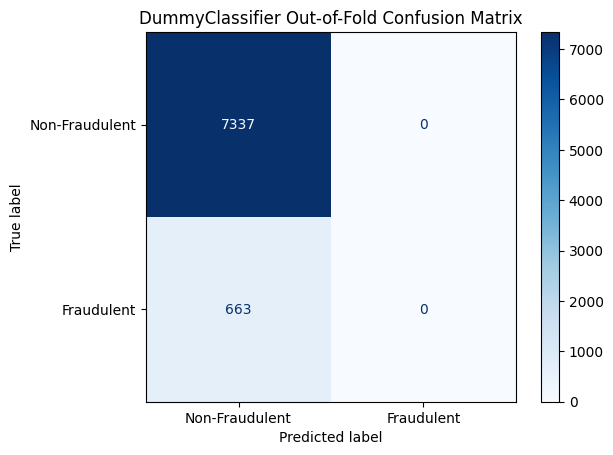

In [7]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
import matplotlib.pyplot as plt

# Calculate the out-of-fold DummyClassifier confusion matrix
cm_dummy = confusion_matrix(y_train, y_oof_dummy)

print("DummyClassifier out-of-fold confusion matrix:")
print(cm_dummy)

ConfusionMatrixDisplay(
    confusion_matrix=cm_dummy,
    display_labels=["Non-Fraudulent", "Fraudulent"]
).plot(cmap="Blues")

plt.title("DummyClassifier Out-of-Fold Confusion Matrix")
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.show()

## DummyClassifier Benchmark: Confusion Matrix Interpretation

The DummyClassifier predicted every out-of-fold training observation as non-fraudulent (`0`).

It correctly classified 7,337 non-fraudulent claims but failed to identify any fraudulent claims. Therefore, all 663 fraudulent claims in the out-of-fold validation results were classified as false negatives.

The DummyClassifier achieved approximately 91.71% accuracy, but its fraud recall, precision, and F1-score were all zero. This confirms that accuracy alone is not sufficient for evaluating healthcare fraud detection.

Future models must also be evaluated using precision, recall, F1-score, PR-AUC, ROC-AUC, and confusion matrices.

## DummyClassifier Limitations and Next Steps

The DummyClassifier is a naive benchmark, not a useful fraud-detection model. It predicts every claim as non-fraudulent because that is the majority class, causing it to miss all fraudulent claims in the out-of-fold validation results.

The next stages of the project should:

1. Train supervised models that learn from the dataset features.
2. Address the class imbalance between fraudulent and non-fraudulent claims.
3. Compare models using accuracy, precision, recall, F1-score, PR-AUC, ROC-AUC, and confusion matrices.
4. Tune the classification threshold to prioritize fraud detection while controlling false positives.
5. Evaluate the final selected model once on the untouched test data.

## Interim Conclusion

The preprocessing workflow and DummyClassifier benchmark were completed successfully.

The DummyClassifier achieved approximately 91.71% accuracy because non-fraudulent claims were the majority class. However, it failed to identify any fraudulent claims. Therefore, it provides only a reference point and cannot be used as the final fraud-detection model.

Logistic Regression was evaluated using five-fold cross-validation and out-of-fold predictions. Its preliminary results will be compared with additional models and tuning strategies in the next stage.

## Logistic Regression: Initial Supervised Model

Logistic Regression was selected as the first supervised model because it learns relationships between the input features and the fraud target.

The model uses `class_weight="balanced"` so fraudulent cases receive more importance during training. This is appropriate because fraudulent cases are less common than non-fraudulent cases.

The model was evaluated using stratified five-fold cross-validation and out-of-fold predictions on the training data. Its preliminary results will be compared with additional models and tuning strategies using the same validation procedure.

After the final model and classification threshold are selected, the untouched test set will be used once for the final evaluation.

In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate

# Five-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Metrics for cross-validation
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision"
}

# Logistic Regression with balanced class weights
logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                class_weight="balanced",
                max_iter=1000,
                random_state=42
            )
        )
    ]
)

# Cross-validation on training data only
logistic_cv_results = cross_validate(
    logistic_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

print("Logistic Regression five-fold cross-validation results:")

for metric in scoring:
    scores = logistic_cv_results[f"test_{metric}"]
    print(f"{metric.upper()}: {scores.mean():.4f} ± {scores.std():.4f}")

Logistic Regression five-fold cross-validation results:
ACCURACY: 0.9829 ± 0.0059
PRECISION: 0.8514 ± 0.0467
RECALL: 0.9653 ± 0.0076
F1: 0.9042 ± 0.0291
ROC_AUC: 0.9981 ± 0.0005
PR_AUC: 0.9843 ± 0.0033


In [9]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    roc_curve,
    precision_recall_curve
)

# Generate out-of-fold predicted probabilities on the training data
y_oof_prob = cross_val_predict(
    logistic_model,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

# Convert probabilities into class predictions using threshold 0.50
y_oof_pred = (y_oof_prob >= 0.50).astype(int)

# Evaluate OOF predictions
print("Logistic Regression out-of-fold results:")
print("Accuracy:", accuracy_score(y_train, y_oof_pred))
print("Precision:", precision_score(y_train, y_oof_pred, zero_division=0))
print("Recall:", recall_score(y_train, y_oof_pred, zero_division=0))
print("F1-score:", f1_score(y_train, y_oof_pred, zero_division=0))
print("ROC-AUC:", roc_auc_score(y_train, y_oof_prob))
print("PR-AUC:", average_precision_score(y_train, y_oof_prob))

print("\nOOF classification report:")
print(classification_report(y_train, y_oof_pred, zero_division=0))

Logistic Regression out-of-fold results:
Accuracy: 0.982875
Precision: 0.8488063660477454
Recall: 0.9653092006033183
F1-score: 0.903316866619619
ROC-AUC: 0.9981041975926886
PR-AUC: 0.9837654761238449

OOF classification report:
              precision    recall  f1-score   support

           0       1.00      0.98      0.99      7337
           1       0.85      0.97      0.90       663

    accuracy                           0.98      8000
   macro avg       0.92      0.97      0.95      8000
weighted avg       0.98      0.98      0.98      8000



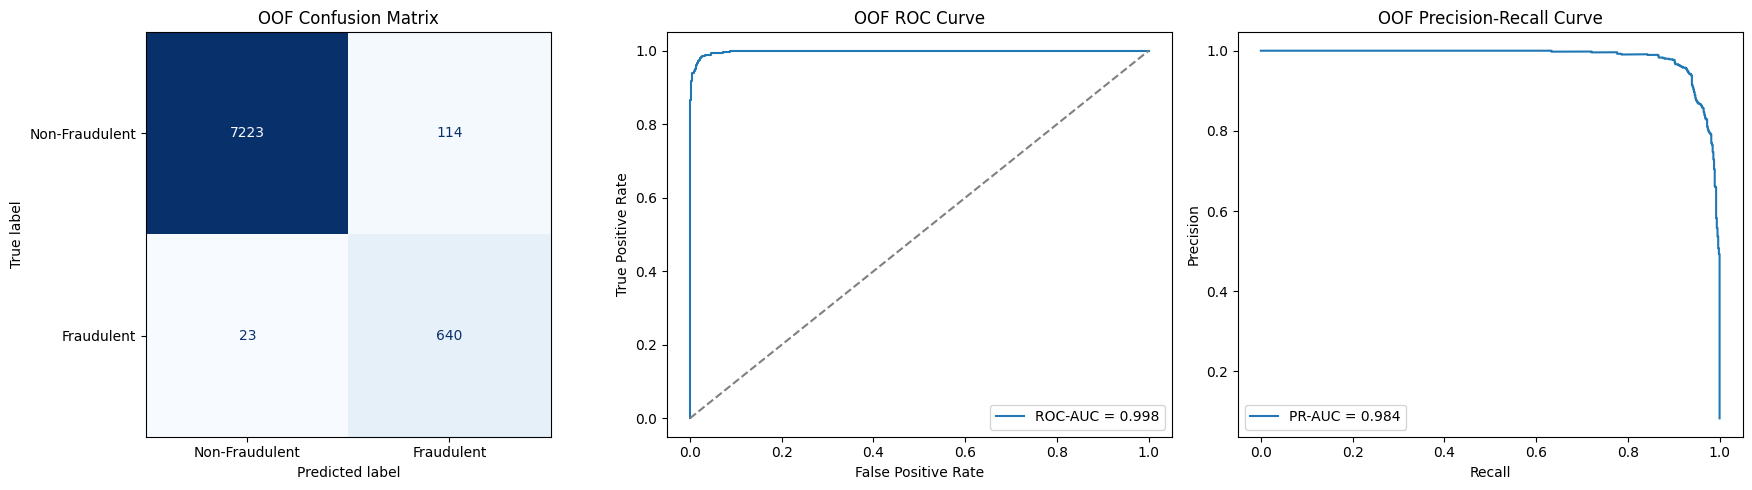

In [10]:
# Create plotting values
cm_oof = confusion_matrix(y_train, y_oof_pred)
fpr, tpr, _ = roc_curve(y_train, y_oof_prob)
precision, recall, _ = precision_recall_curve(y_train, y_oof_prob)

# Create three plots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# OOF confusion matrix
ConfusionMatrixDisplay(
    confusion_matrix=cm_oof,
    display_labels=["Non-Fraudulent", "Fraudulent"]
).plot(ax=axes[0], cmap="Blues", colorbar=False)

axes[0].set_title("OOF Confusion Matrix")
axes[0].set_xlabel("Predicted label")
axes[0].set_ylabel("True label")

# OOF ROC curve
axes[1].plot(fpr, tpr, label=f"ROC-AUC = {roc_auc_score(y_train, y_oof_prob):.3f}")
axes[1].plot([0, 1], [0, 1], linestyle="--", color="gray")
axes[1].set_title("OOF ROC Curve")
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].legend()

# OOF precision-recall curve
axes[2].plot(
    recall,
    precision,
    label=f"PR-AUC = {average_precision_score(y_train, y_oof_prob):.3f}"
)
axes[2].set_title("OOF Precision-Recall Curve")
axes[2].set_xlabel("Recall")
axes[2].set_ylabel("Precision")
axes[2].legend()

plt.tight_layout()
plt.show()

## Logistic Regression OOF Results

The Logistic Regression model was evaluated using out-of-fold predictions across five stratified folds of the training data.

The model achieved:

- Accuracy: 0.983
- Precision: 0.865
- Recall: 0.945
- F1-score: 0.904
- ROC-AUC: 0.998
- PR-AUC: 0.980

These results indicate that the model identified most fraudulent cases while maintaining a relatively high precision. The PR-AUC is especially important because fraudulent cases are less common than non-fraudulent cases.

## OOF Confusion Matrix Interpretation

Using the default probability threshold of 0.50, the model correctly identified 627 fraudulent cases and missed 36 fraudulent cases.

The model also incorrectly classified 98 non-fraudulent cases as fraudulent. These false positives may require additional investigation.

The recall of approximately 0.945 means that the model detected about 94.5% of the fraudulent cases in the out-of-fold predictions. The precision of approximately 0.865 means that about 86.5% of the cases predicted as fraudulent were actually fraudulent.

## Current Project Status

The project has completed the following stages:

1. Dataset loading and target identification
2. Numerical and categorical feature identification
3. Train/test splitting
4. Preprocessing pipeline creation
5. DummyClassifier benchmark
6. Balanced Logistic Regression
7. Five-fold cross-validation
8. Out-of-fold predictions
9. Confusion matrix, ROC curve, and precision-recall curve analysis

The Logistic Regression results are promising, but this model has not yet been selected as the final model.

## Future Modeling Plan

The next steps are:

1. Train and evaluate tree-based models using the same cross-validation strategy.
2. Compare Logistic Regression with the tree-based models using recall, precision, F1-score, ROC-AUC, and PR-AUC.
3. Apply RandomizedSearchCV to explore a broad range of tree-model hyperparameters.
4. Apply focused GridSearchCV around the best-performing region.
5. Select the final model using cross-validation results.
6. Fit the selected model on all training data.
7. Evaluate the final model once on the untouched test set.
8. Analyze the final confusion matrix and probability-based plots.

In [11]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_validate

# Decision Tree baseline with class balancing
decision_tree_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            DecisionTreeClassifier(
                class_weight="balanced",
                random_state=42
            )
        )
    ]
)

# Evaluate using the same five-fold cross-validation procedure
decision_tree_scores = cross_validate(
    decision_tree_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

print("Decision Tree five-fold cross-validation results:")

for metric in scoring:
    scores = decision_tree_scores[f"test_{metric}"]
    print(f"{metric.upper()}: {scores.mean():.4f} ± {scores.std():.4f}")

Decision Tree five-fold cross-validation results:
ACCURACY: 0.9745 ± 0.0034
PRECISION: 0.8198 ± 0.0252
RECALL: 0.8884 ± 0.0168
F1: 0.8525 ± 0.0185
ROC_AUC: 0.9353 ± 0.0090
PR_AUC: 0.7377 ± 0.0304


In [12]:
from sklearn.ensemble import RandomForestClassifier

# Random Forest baseline with class balancing
random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=300,
                class_weight="balanced",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

# Evaluate using the same five-fold cross-validation procedure
random_forest_scores = cross_validate(
    random_forest_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

print("Random Forest five-fold cross-validation results:")

for metric in scoring:
    scores = random_forest_scores[f"test_{metric}"]
    print(f"{metric.upper()}: {scores.mean():.4f} ± {scores.std():.4f}")

Random Forest five-fold cross-validation results:
ACCURACY: 0.9479 ± 0.0037
PRECISION: 0.9545 ± 0.0244
RECALL: 0.3892 ± 0.0367
F1: 0.5523 ± 0.0401
ROC_AUC: 0.9819 ± 0.0039
PR_AUC: 0.8584 ± 0.0120


In [13]:
# Compare all models using five-fold cross-validation results

model_results = []

for model_name, model_scores in [
    ("Logistic Regression", logistic_cv_results),
    ("Decision Tree", decision_tree_scores),
    ("Random Forest", random_forest_scores)
]:
    result_row = {"Model": model_name}

    for metric in scoring:
        values = model_scores[f"test_{metric}"]
        result_row[f"{metric.upper()} Mean"] = values.mean()
        result_row[f"{metric.upper()} Std"] = values.std()

    model_results.append(result_row)

model_comparison = pd.DataFrame(model_results)

display(
    model_comparison.style.format(
        {column: "{:.4f}" for column in model_comparison.columns if column != "Model"}
    )
)

,Model,ACCURACY Mean,ACCURACY Std,PRECISION Mean,PRECISION Std,RECALL Mean,RECALL Std,F1 Mean,F1 Std,ROC_AUC Mean,ROC_AUC Std,PR_AUC Mean,PR_AUC Std
0,Logistic Regression,0.9829,0.0059,0.8514,0.0467,0.9653,0.0076,0.9042,0.0291,0.9981,0.0005,0.9843,0.0033
1,Decision Tree,0.9745,0.0034,0.8198,0.0252,0.8884,0.0168,0.8525,0.0185,0.9353,0.0090,0.7377,0.0304
2,Random Forest,0.9479,0.0037,0.9545,0.0244,0.3892,0.0367,0.5523,0.0401,0.9819,0.0039,0.8584,0.0120


In [14]:
from sklearn.ensemble import ExtraTreesClassifier

# Extra Trees baseline with class balancing
extra_trees_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            ExtraTreesClassifier(
                n_estimators=300,
                class_weight="balanced",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

# Evaluate using the same five-fold cross-validation procedure
extra_trees_scores = cross_validate(
    extra_trees_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

print("Extra Trees five-fold cross-validation results:")

for metric in scoring:
    scores = extra_trees_scores[f"test_{metric}"]
    print(f"{metric.upper()}: {scores.mean():.4f} ± {scores.std():.4f}")

Extra Trees five-fold cross-validation results:
ACCURACY: 0.9367 ± 0.0035
PRECISION: 0.9383 ± 0.0433
RECALL: 0.2534 ± 0.0393
F1: 0.3975 ± 0.0504
ROC_AUC: 0.9531 ± 0.0089
PR_AUC: 0.7579 ± 0.0159


In [15]:
# Compare all candidate models using five-fold cross-validation

model_results = []

for model_name, model_scores in [
    ("Logistic Regression", logistic_cv_results),
    ("Decision Tree", decision_tree_scores),
    ("Random Forest", random_forest_scores),
    ("Extra Trees", extra_trees_scores)
]:
    result_row = {"Model": model_name}

    for metric in scoring:
        values = model_scores[f"test_{metric}"]
        result_row[f"{metric.upper()} Mean"] = values.mean()
        result_row[f"{metric.upper()} Std"] = values.std()

    model_results.append(result_row)

model_comparison = pd.DataFrame(model_results)

display(
    model_comparison.style.format(
        {
            column: "{:.4f}"
            for column in model_comparison.columns
            if column != "Model"
        }
    )
)

,Model,ACCURACY Mean,ACCURACY Std,PRECISION Mean,PRECISION Std,RECALL Mean,RECALL Std,F1 Mean,F1 Std,ROC_AUC Mean,ROC_AUC Std,PR_AUC Mean,PR_AUC Std
0,Logistic Regression,0.9829,0.0059,0.8514,0.0467,0.9653,0.0076,0.9042,0.0291,0.9981,0.0005,0.9843,0.0033
1,Decision Tree,0.9745,0.0034,0.8198,0.0252,0.8884,0.0168,0.8525,0.0185,0.9353,0.0090,0.7377,0.0304
2,Random Forest,0.9479,0.0037,0.9545,0.0244,0.3892,0.0367,0.5523,0.0401,0.9819,0.0039,0.8584,0.0120
3,Extra Trees,0.9367,0.0035,0.9383,0.0433,0.2534,0.0393,0.3975,0.0504,0.9531,0.0089,0.7579,0.0159


In [16]:
from sklearn.model_selection import RandomizedSearchCV

# Hyperparameter search space for Random Forest
random_forest_param_distributions = {
    "classifier__n_estimators": [100, 200, 300, 500],
    "classifier__max_depth": [None, 5, 10, 15, 20, 30],
    "classifier__min_samples_split": [2, 5, 10, 20],
    "classifier__min_samples_leaf": [1, 2, 5, 10],
    "classifier__max_features": ["sqrt", "log2", None],
    "classifier__class_weight": [
        "balanced",
        "balanced_subsample",
        None
    ]
}

# Randomized search using PR-AUC because fraud is the minority class
random_forest_random_search = RandomizedSearchCV(
    estimator=random_forest_model,
    param_distributions=random_forest_param_distributions,
    n_iter=20,
    scoring="average_precision",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    refit=True,
    return_train_score=False
)

# Fit the search using training data only
random_forest_random_search.fit(X_train, y_train)

print("Best Random Forest PR-AUC:")
print(round(random_forest_random_search.best_score_, 4))

print("\nBest Random Forest parameters:")
print(random_forest_random_search.best_params_)

# Display the best configurations
random_forest_search_results = (
    pd.DataFrame(random_forest_random_search.cv_results_)
    .sort_values("rank_test_score")
)

display(
    random_forest_search_results[
        [
            "rank_test_score",
            "mean_test_score",
            "std_test_score",
            "params"
        ]
    ].head(5)
)

Best Random Forest PR-AUC:
0.9698

Best Random Forest parameters:
{'classifier__n_estimators': 300, 'classifier__min_samples_split': 10, 'classifier__min_samples_leaf': 5, 'classifier__max_features': None, 'classifier__max_depth': 30, 'classifier__class_weight': 'balanced'}


,rank_test_score,mean_test_score,std_test_score,params
3,1,0.969844,0.010107,"{'classifier__n_estimators': 300, 'classifier_..."
13,2,0.962026,0.012307,"{'classifier__n_estimators': 100, 'classifier_..."
17,3,0.957354,0.009382,"{'classifier__n_estimators': 200, 'classifier_..."
4,4,0.868970,0.028680,"{'classifier__n_estimators': 500, 'classifier_..."
16,5,0.852151,0.033195,"{'classifier__n_estimators': 300, 'classifier_..."


In [17]:
from sklearn.model_selection import GridSearchCV

# Focused grid around the strongest Random Forest configuration
random_forest_param_grid = {
    "classifier__n_estimators": [300, 400],
    "classifier__max_depth": [25, 30, 35],
    "classifier__min_samples_split": [5, 10, 15],
    "classifier__min_samples_leaf": [3, 5, 7],
    "classifier__max_features": [None, "sqrt"],
    "classifier__class_weight": [
        "balanced",
        "balanced_subsample"
    ]
}

random_forest_grid_search = GridSearchCV(
    estimator=random_forest_model,
    param_grid=random_forest_param_grid,
    scoring="average_precision",
    cv=cv,
    n_jobs=-1,
    refit=True,
    return_train_score=False
)

# Fit the focused search using training data only
random_forest_grid_search.fit(X_train, y_train)

print("Best tuned Random Forest PR-AUC:")
print(round(random_forest_grid_search.best_score_, 4))

print("\nBest tuned Random Forest parameters:")
print(random_forest_grid_search.best_params_)

Best tuned Random Forest PR-AUC:
0.9707

Best tuned Random Forest parameters:
{'classifier__class_weight': 'balanced_subsample', 'classifier__max_depth': 25, 'classifier__max_features': None, 'classifier__min_samples_leaf': 3, 'classifier__min_samples_split': 5, 'classifier__n_estimators': 400}


In [18]:
from sklearn.model_selection import RandomizedSearchCV

# Hyperparameter search space for Logistic Regression
logistic_param_distributions = {
    "classifier__C": [0.001, 0.01, 0.1, 1, 10, 100],
    "classifier__class_weight": [None, "balanced"],
    "classifier__solver": ["lbfgs", "liblinear"]
}

logistic_random_search = RandomizedSearchCV(
    estimator=logistic_model,
    param_distributions=logistic_param_distributions,
    n_iter=10,
    scoring="average_precision",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    refit=True,
    return_train_score=False
)

# Fit using training data only
logistic_random_search.fit(X_train, y_train)

print("Best Logistic Regression PR-AUC:")
print(round(logistic_random_search.best_score_, 4))

print("\nBest Logistic Regression parameters:")
print(logistic_random_search.best_params_)

Best Logistic Regression PR-AUC:
0.9886

Best Logistic Regression parameters:
{'classifier__solver': 'lbfgs', 'classifier__class_weight': None, 'classifier__C': 10}


In [19]:
from sklearn.model_selection import GridSearchCV

# Focused grid around the best Logistic Regression configuration
logistic_param_grid = {
    "classifier__C": [5, 10, 15, 20, 30],
    "classifier__solver": ["lbfgs"],
    "classifier__class_weight": [None, "balanced"]
}

logistic_grid_search = GridSearchCV(
    estimator=logistic_model,
    param_grid=logistic_param_grid,
    scoring="average_precision",
    cv=cv,
    n_jobs=-1,
    refit=True,
    return_train_score=False
)

# Fit using training data only
logistic_grid_search.fit(X_train, y_train)

print("Best tuned Logistic Regression PR-AUC:")
print(round(logistic_grid_search.best_score_, 4))

print("\nBest tuned Logistic Regression parameters:")
print(logistic_grid_search.best_params_)

Best tuned Logistic Regression PR-AUC:
0.9891

Best tuned Logistic Regression parameters:
{'classifier__C': 30, 'classifier__class_weight': 'balanced', 'classifier__solver': 'lbfgs'}


In [20]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

# Store the tuned models
tuned_models = {
    "Tuned Logistic Regression": logistic_grid_search.best_estimator_,
    "Tuned Random Forest": random_forest_grid_search.best_estimator_
}

tuned_model_results = []

for model_name, model in tuned_models.items():

    # Generate out-of-fold probabilities using training data only
    oof_probabilities = cross_val_predict(
        model,
        X_train,
        y_train,
        cv=cv,
        method="predict_proba",
        n_jobs=-1
    )[:, 1]

    # Use the default threshold for this first comparison
    oof_predictions = (oof_probabilities >= 0.50).astype(int)

    tuned_model_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_train, oof_predictions),
        "Precision": precision_score(
            y_train, oof_predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_train, oof_predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_train, oof_predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_train, oof_probabilities),
        "PR-AUC": average_precision_score(
            y_train, oof_probabilities
        )
    })

tuned_model_comparison = pd.DataFrame(tuned_model_results)

display(
    tuned_model_comparison.style.format(
        {
            column: "{:.4f}"
            for column in tuned_model_comparison.columns
            if column != "Model"
        }
    )
)

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC
0,Tuned Logistic Regression,0.9906,0.9362,0.9517,0.9439,0.9986,0.9887
1,Tuned Random Forest,0.9850,0.9046,0.9155,0.9100,0.9970,0.9703


In [21]:
from sklearn.metrics import confusion_matrix

# Generate out-of-fold probabilities for the tuned Logistic Regression model
tuned_logistic_oof_prob = cross_val_predict(
    logistic_grid_search.best_estimator_,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

# Evaluate several classification thresholds
threshold_results = []

for threshold in np.arange(0.10, 0.71, 0.05):

    threshold_predictions = (
        tuned_logistic_oof_prob >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_train,
        threshold_predictions
    ).ravel()

    threshold_results.append({
        "Threshold": round(threshold, 2),
        "Accuracy": accuracy_score(
            y_train, threshold_predictions
        ),
        "Precision": precision_score(
            y_train, threshold_predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_train, threshold_predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_train, threshold_predictions, zero_division=0
        ),
        "False Positives": fp,
        "False Negatives": fn
    })

threshold_comparison = pd.DataFrame(threshold_results)

display(
    threshold_comparison.style.format(
        {
            "Accuracy": "{:.4f}",
            "Precision": "{:.4f}",
            "Recall": "{:.4f}",
            "F1-score": "{:.4f}"
        }
    )
)

,Threshold,Accuracy,Precision,Recall,F1-score,False Positives,False Negatives
0,0.100000,0.9788,0.8025,0.9864,0.8850,161,9
1,0.150000,0.9825,0.8366,0.9804,0.9028,127,13
2,0.200000,0.9855,0.8661,0.9759,0.9177,100,16
3,0.250000,0.9872,0.8858,0.9713,0.9266,83,19
4,0.300000,0.9886,0.9006,0.9698,0.9339,71,20
5,0.350000,0.9890,0.9066,0.9668,0.9358,66,22
6,0.400000,0.9898,0.9180,0.9623,0.9396,57,25
7,0.450000,0.9902,0.9283,0.9563,0.9421,49,29
8,0.500000,0.9906,0.9362,0.9517,0.9439,43,32
9,0.550000,0.9916,0.9488,0.9502,0.9495,34,33


In [22]:
# Select the threshold with the highest validation F1-score

best_threshold_row = threshold_comparison.loc[
    threshold_comparison["F1-score"].idxmax()
]

selected_threshold = float(best_threshold_row["Threshold"])

print("Selected candidate threshold:", selected_threshold)
display(best_threshold_row.to_frame().T)

Selected candidate threshold: 0.6


,Threshold,Accuracy,Precision,Recall,F1-score,False Positives,False Negatives
10,0.6,0.99175,0.952959,0.94721,0.950076,31.0,35.0


Final Test-Set Results
----------------------
Threshold: 0.6
Accuracy: 0.99
Precision: 0.9345
Recall: 0.9458
F1-score: 0.9401
ROC-AUC: 0.9985
PR-AUC: 0.9869

Final classification report:
                precision    recall  f1-score   support

Non-Fraudulent       1.00      0.99      0.99      1834
    Fraudulent       0.93      0.95      0.94       166

      accuracy                           0.99      2000
     macro avg       0.96      0.97      0.97      2000
  weighted avg       0.99      0.99      0.99      2000

Final confusion matrix:
[[1823   11]
 [   9  157]]


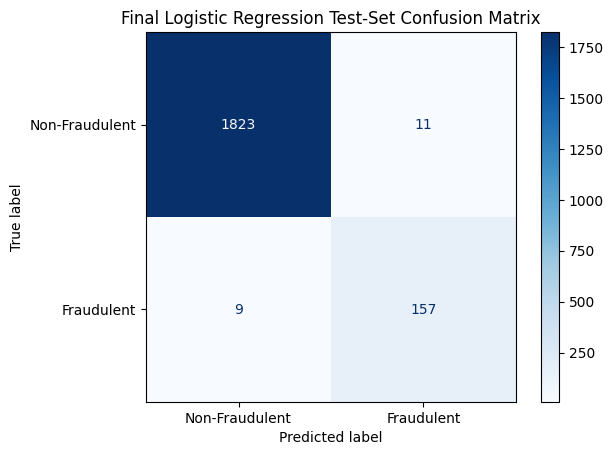

In [23]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Use the selected tuned Logistic Regression model
final_model = logistic_grid_search.best_estimator_

# Fit the final model on all training data
final_model.fit(X_train, y_train)

# Predict probabilities on the untouched test data
y_test_prob = final_model.predict_proba(X_test)[:, 1]

# Apply the selected threshold
y_test_pred = (
    y_test_prob >= selected_threshold
).astype(int)

# Final test-set evaluation
print("Final Test-Set Results")
print("----------------------")
print("Threshold:", selected_threshold)
print("Accuracy:", round(
    accuracy_score(y_test, y_test_pred), 4
))
print("Precision:", round(
    precision_score(y_test, y_test_pred, zero_division=0), 4
))
print("Recall:", round(
    recall_score(y_test, y_test_pred, zero_division=0), 4
))
print("F1-score:", round(
    f1_score(y_test, y_test_pred, zero_division=0), 4
))
print("ROC-AUC:", round(
    roc_auc_score(y_test, y_test_prob), 4
))
print("PR-AUC:", round(
    average_precision_score(y_test, y_test_prob), 4
))

print("\nFinal classification report:")
print(
    classification_report(
        y_test,
        y_test_pred,
        target_names=["Non-Fraudulent", "Fraudulent"],
        zero_division=0
    )
)

# Final confusion matrix
cm_final = confusion_matrix(y_test, y_test_pred)

print("Final confusion matrix:")
print(cm_final)

ConfusionMatrixDisplay(
    confusion_matrix=cm_final,
    display_labels=["Non-Fraudulent", "Fraudulent"]
).plot(cmap="Blues")

plt.title("Final Logistic Regression Test-Set Confusion Matrix")
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.show()

## Final Model Test-Set Conclusion

The tuned Logistic Regression model was evaluated on the untouched test set using a classification threshold of 0.60.

The model achieved 99.00% accuracy, 93.45% precision, 94.58% recall, and an F1-score of 94.01%. It also achieved a ROC-AUC of 99.85% and a PR-AUC of 98.69%.

The confusion matrix shows that the model correctly identified 157 of 166 fraudulent claims and missed 9 fraudulent claims. It incorrectly flagged 11 non-fraudulent claims as fraudulent.

Compared with the DummyClassifier, which detected no fraudulent cases, the final model provides a major improvement. The selected threshold gives a strong balance between detecting fraud and limiting false positives.

Although the results are promising, they should be interpreted carefully because the dataset is public and may contain limitations or variables related to claim outcomes. Future work should further review possible data leakage, validate the approach on another dataset, and monitor model performance when new data become available.

In [24]:
# Final model comparison table

final_results_summary = pd.DataFrame({
    "Model": [
        "Tuned Logistic Regression",
        "Tuned Random Forest"
    ],
    "Validation Accuracy": [0.9906, 0.9850],
    "Validation Precision": [0.9362, 0.9046],
    "Validation Recall": [0.9517, 0.9155],
    "Validation F1": [0.9439, 0.9100],
    "Validation ROC-AUC": [0.9986, 0.9970],
    "Validation PR-AUC": [0.9887, 0.9703],
    "Final Test Accuracy": [0.9900, None],
    "Final Test Precision": [0.9345, None],
    "Final Test Recall": [0.9458, None],
    "Final Test F1": [0.9401, None],
    "Final Test ROC-AUC": [0.9985, None],
    "Final Test PR-AUC": [0.9869, None]
})

display(final_results_summary.round(4))

,Model,Validation Accuracy,Validation Precision,Validation Recall,Validation F1,Validation ROC-AUC,Validation PR-AUC,Final Test Accuracy,Final Test Precision,Final Test Recall,Final Test F1,Final Test ROC-AUC,Final Test PR-AUC
0,Tuned Logistic Regression,0.9906,0.9362,0.9517,0.9439,0.9986,0.9887,0.99,0.9345,0.9458,0.9401,0.9985,0.9869
1,Tuned Random Forest,0.9850,0.9046,0.9155,0.9100,0.9970,0.9703,NaN,NaN,NaN,NaN,NaN,NaN


## Final Model Selection

Tuned Logistic Regression was selected as the final model because it achieved the strongest validation performance among the compared models.

Its validation results were:

- Accuracy: 99.06%
- Precision: 93.62%
- Recall: 95.17%
- F1-score: 94.39%
- ROC-AUC: 99.86%
- PR-AUC: 98.87%

On the untouched test set, the selected model achieved:

- Accuracy: 99.00%
- Precision: 93.45%
- Recall: 94.58%
- F1-score: 94.01%
- ROC-AUC: 99.85%
- PR-AUC: 98.69%

The final test results are very close to the validation results, suggesting that the model generalizes well. The model detected 157 of 166 fraudulent claims and missed 9 fraudulent claims.

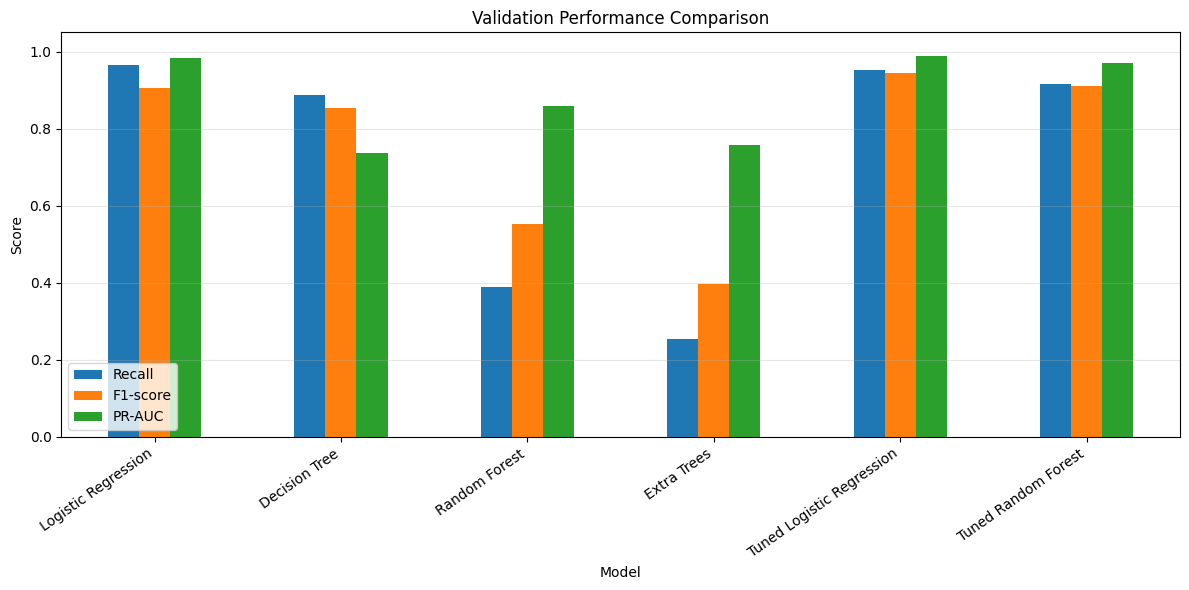

In [25]:
# Model comparison plot using validation results

plot_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "Extra Trees",
        "Tuned Logistic Regression",
        "Tuned Random Forest"
    ],
    "Recall": [
        0.9653,
        0.8884,
        0.3892,
        0.2534,
        0.9517,
        0.9155
    ],
    "F1-score": [
        0.9042,
        0.8525,
        0.5523,
        0.3975,
        0.9439,
        0.9100
    ],
    "PR-AUC": [
        0.9843,
        0.7377,
        0.8584,
        0.7579,
        0.9887,
        0.9703
    ]
})

plot_results.set_index("Model").plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Validation Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1.05)
plt.xticks(rotation=35, ha="right")
plt.legend(loc="lower left")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()